In [1]:
import random
import matplotlib.pyplot as plt

random.seed()


In [2]:
# initial population
def generate_population(pop_size, chrom_length):
    population = []
    for _ in range(pop_size):
        chromosome = []
        for _ in range(chrom_length):
            gene = random.randint(0, 1)
            chromosome.append(gene)
        population.append(chromosome)
    return population


In [5]:
# objective function
def objective_function(value, individual):
          
    return sum(v * x for v, x in zip(value, individual) )

In [7]:
# total weight
def total_weight(weight, individual):
    
    return sum(w * x for w, x in zip(weight, individual))


In [9]:
# fitness function
def fitness_function(individual, value, weight, capacity, alpha):
    objective_func = objective_function(value, individual)
    violation = max(0, total_weight(weight, individual) - capacity)  
    fitness = objective_func - alpha * violation
    return fitness

In [11]:
# rulette wheele selection
def roulette_wheel_selection(population, fitnesses):
    total_fitness = sum(fitnesses)
    
    # normalizing each fitness
    normalized_fitnesses = [f / total_fitness for f in fitnesses] 
    
    # cumulative distribution for individuals
    p_range = 0.0
    cumulative = []
    for n in normalized_fitnesses: 
        p_range += n
        cumulative.append(p_range)
        
    # selecting an individual    
    p_selection = random.random()
    for i, c in enumerate(cumulative):
        if p_selection < c:
            return population[i]
        
    return population[-1]

In [13]:
# one point crossover
def crossover(parent1, parent2, crossover_rate):
    if random.random() < crossover_rate:
        point = random.randint(1, len(parent1) - 1) # cutting point 
        child1 = parent1[:point] + parent2[point:]
        child2 = parent2[:point] + parent1[point:]
    else:
        child1, child2 = parent1[:], parent2[:]
    return child1, child2


In [15]:
# mutation
def mutate(individual, mutation_rate):
    for i in range(len(individual)):
        if random.random() < mutation_rate:
            individual[i] = 1 - individual[i]
    return individual

In [17]:
# adaptive alpha
def adaptive_alpha(alpha, population, weights, Q):
       
    pop_size = len(population)
    if pop_size == 0:
        return alpha, 0.0

    # feasible percentage
    feasible_count = sum(1 for ind in population if total_weight(weights, ind) <= Q)
    feasible_percentage = feasible_count / pop_size

    # decision to update alpha
    if 0.25 <= feasible_percentage <= 0.30:
         new_alpha = alpha
        
    elif feasible_percentage < 0.25:
        new_alpha = alpha * 0.95
        
    else:  # feasible_percentage > 30%
        new_alpha = alpha * 1.05

    # constrain alpha between min and max
    new_alpha = max(0.1, min(new_alpha, 10))
    
    return new_alpha 


In [19]:
# running genetic algorithm
def genetic_algorithm():
    weights = [5, 8, 1, 3, 7, 4, 9, 2, 6, 5.5]
    values = [10, 14, 5, 12, 17, 9, 18, 16, 11, 13]
    Q = 15
    pop_size = 100
    chrom_length = len(weights)
    generations = 200
    mutation_rate = 0.2
    crossover_rate = 1.0
    alpha = 1.0  # initialing alpha
   

    population = generate_population(pop_size, chrom_length)
    
    best_fitness_over_gens = []
    avg_fitness_over_gens = []
    
    for gen in range(generations):
        fitnesses = [fitness_function(ind, values, weights, Q, alpha) for ind in population]
        best_individual = population[fitnesses.index(max(fitnesses))]
        best_fitness = max(fitnesses)
        best_fitness_over_gens.append(best_fitness)
        avg_fitness_over_gens.append(sum(fitnesses)/len(fitnesses))  # 

      
        # update alpha
        alpha = adaptive_alpha(alpha, population, weights, Q)    
         
        # elitisim 
        elitisim_size = int(0.05 * pop_size)
        sorted_population = [ind for _, ind in sorted(zip(fitnesses, population), reverse=True)]
        new_population = [ind[:] for ind in sorted_population[:elitisim_size]]
    
        while len(new_population) < pop_size:
            parent1 = roulette_wheel_selection(population, fitnesses)
            parent2 = roulette_wheel_selection(population, fitnesses)
            child1, child2 = crossover(parent1, parent2, crossover_rate)
            mutate(child1, mutation_rate)
            mutate(child2, mutation_rate)
            new_population.extend([child1, child2])
    
        population = new_population[:pop_size]
    
    return best_fitness_over_gens, avg_fitness_over_gens

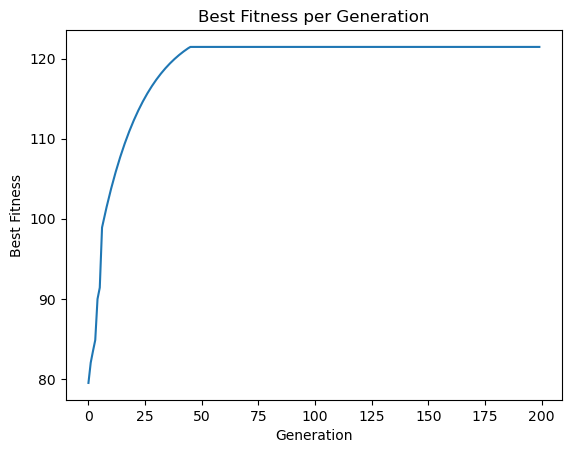

In [21]:
best_fitness_over_gens, _ = genetic_algorithm()
plt.plot(best_fitness_over_gens)
plt.title("Best Fitness per Generation")
plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.show()

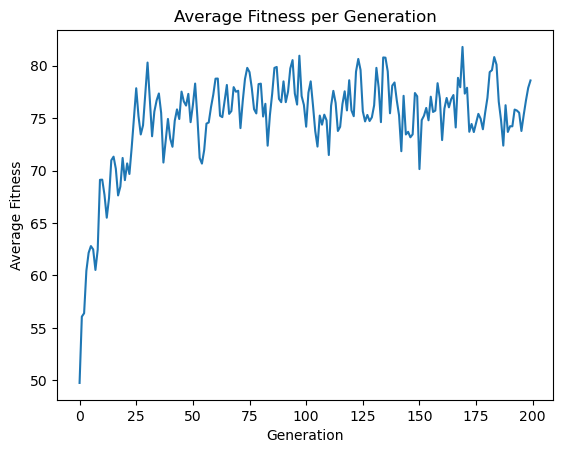

In [23]:
_, avg_fitness_over_gens = genetic_algorithm()
plt.plot(avg_fitness_over_gens)
plt.title("Average Fitness per Generation")
plt.xlabel("Generation")
plt.ylabel("Average Fitness")
plt.show()

In [25]:
import numpy as np
all_runs_best = []  
num_runs = 30

for _ in range(num_runs):
    best_over_gens, _ = genetic_algorithm()
    all_runs_best.append(best_over_gens)

# convert to numpy array to calculate the mean
all_runs_best = np.array(all_runs_best)  # 2D numpy array: rows = num_runs , columns = generations
mean_best_over_gens = np.mean(all_runs_best, axis=0)  # mean over 200 generation

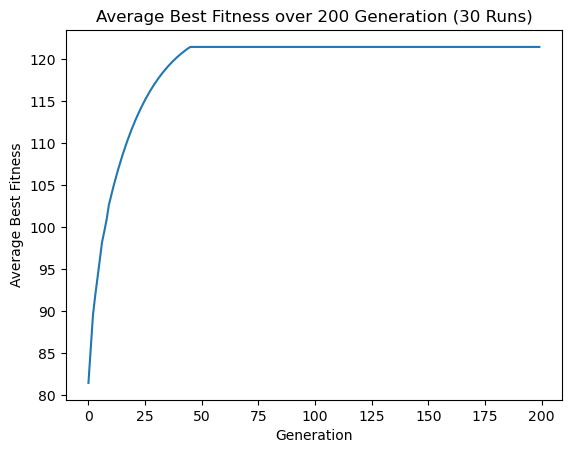

In [26]:
plt.plot(mean_best_over_gens)
plt.title("Average Best Fitness over 200 Generation (30 Runs)")
plt.xlabel("Generation")
plt.ylabel("Average Best Fitness")
plt.show()